## Filter intersection images

Dieses Notebook filtert den CityScapes Datensatz nach Bildern und Annotationen bei Kreuzungen, mit Hilfe der CSV-Dateien, die in `intersection_image_matching.ipynb` erzeugt wurden. In den CSV-Dateien sind jeweils alle `image_id's` jener Bilder enthalten, deren GPS-Daten innerhalb eines Intersection-Radius liegen.

Zuerst:
- definieren wir die Pfade für die `images_within_intersections` CSV-Dateien
- lesen wir die CSV-Dateien als DataFrame ein

In [1]:
import pandas as pd
from pathlib import Path
from tqdm import tqdm

output_dir = Path("../output")
fine_intersections_3_path = output_dir / "intersection_filtered" / "fine_images_within_intersections_3.csv"
fine_intersections_4_path = output_dir / "intersection_filtered" / "fine_images_within_intersections_4.csv"
coarse_intersections_3_path = output_dir / "intersection_filtered" / "coarse_images_within_intersections_3.csv"
coarse_intersections_4_path = output_dir / "intersection_filtered" / "coarse_images_within_intersections_4.csv"

fine_intersections_3 = pd.read_csv(fine_intersections_3_path)
fine_intersections_4 = pd.read_csv(fine_intersections_4_path)
coarse_intersections_3 = pd.read_csv(coarse_intersections_3_path)
coarse_intersections_4 = pd.read_csv(coarse_intersections_4_path)

Für das spätere Filtern/Kopieren:
- müssen wir die tatsächlichen Dateiendungen für das Image, die farbige Labelmaske sowie die graue Label-Id-Maske an die CityScapes `image_id` anhängen
- die Dateinamen in jeweils einer separaten Spalte im DataFrame speichern
- das ganze für den feinen und groben CityScapes Datensatz durchführen  (`"gtFine"` und `"gtCoarse"`)

In [2]:
image_types  = ["image_file", "color_labels", "label_ids", "label_train_ids"]
file_endings = ["_leftImg8bit.png", "_gtFine_color.png", "_gtFine_labelIds.png", "_gtFine_labelTrainIds.png"]

for image_type, file_ending in zip(image_types, file_endings):
    fine_intersections_3[image_type] = fine_intersections_3["image_id"] + file_ending
    fine_intersections_4[image_type] = fine_intersections_4["image_id"] + file_ending

print(f"gtFine images within intersections of degree 3: {len(fine_intersections_3)}")
print(f"gtFine images within intersections of degree 4: {len(fine_intersections_4)}")
fine_intersections_3.head()

gtFine images within intersections of degree 3: 1655
gtFine images within intersections of degree 4: 576


,Unnamed: 0,split,city,image_id,latitude,longitude,intersection_id,image_file,color_labels,label_ids,label_train_ids
0,1,test,berlin,berlin_000001_000019,52.498672,13.300393,1514,berlin_000001_000019_leftImg8bit.png,berlin_000001_000019_gtFine_color.png,berlin_000001_000019_gtFine_labelIds.png,berlin_000001_000019_gtFine_labelTrainIds.png
1,2,test,berlin,berlin_000002_000019,52.499890,13.306958,1783,berlin_000002_000019_leftImg8bit.png,berlin_000002_000019_gtFine_color.png,berlin_000002_000019_gtFine_labelIds.png,berlin_000002_000019_gtFine_labelTrainIds.png
2,5,test,berlin,berlin_000005_000019,52.496816,13.305182,2742,berlin_000005_000019_leftImg8bit.png,berlin_000005_000019_gtFine_color.png,berlin_000005_000019_gtFine_labelIds.png,berlin_000005_000019_gtFine_labelTrainIds.png
3,6,test,berlin,berlin_000006_000019,52.496830,13.307894,2745,berlin_000006_000019_leftImg8bit.png,berlin_000006_000019_gtFine_color.png,berlin_000006_000019_gtFine_labelIds.png,berlin_000006_000019_gtFine_labelTrainIds.png
4,7,test,berlin,berlin_000007_000019,52.493911,13.310314,2424,berlin_000007_000019_leftImg8bit.png,berlin_000007_000019_gtFine_color.png,berlin_000007_000019_gtFine_labelIds.png,berlin_000007_000019_gtFine_labelTrainIds.png


In [4]:
image_types  = ["image_file", "color_labels", "label_ids", "label_train_ids"]
file_endings = ["_leftImg8bit.png", "_gtCoarse_color.png", "_gtCoarse_labelIds.png", "_gtCoarse_labelTrainIds.png"]

for image_type, file_ending in zip(image_types, file_endings):
    coarse_intersections_3[image_type] = coarse_intersections_3["image_id"] + file_ending
    coarse_intersections_4[image_type] = coarse_intersections_4["image_id"] + file_ending

print(f"gtCoarse images within intersections of degree 3: {len(coarse_intersections_3)}")
print(f"gtCoarse images within intersections of degree 4: {len(coarse_intersections_4)}")
coarse_intersections_3.head()

gtCoarse images within intersections of degree 3: 6269
gtCoarse images within intersections of degree 4: 1912


,Unnamed: 0,split,city,image_id,latitude,longitude,intersection_id,image_file,color_labels,label_ids,label_train_ids
0,0,train_extra,augsburg,augsburg_000000_000000,48.371323,10.886690,2530,augsburg_000000_000000_leftImg8bit.png,augsburg_000000_000000_gtCoarse_color.png,augsburg_000000_000000_gtCoarse_labelIds.png,augsburg_000000_000000_gtCoarse_labelTrainIds.png
1,1,train_extra,augsburg,augsburg_000000_000001,48.371254,10.887023,2530,augsburg_000000_000001_leftImg8bit.png,augsburg_000000_000001_gtCoarse_color.png,augsburg_000000_000001_gtCoarse_labelIds.png,augsburg_000000_000001_gtCoarse_labelTrainIds.png
2,4,train_extra,augsburg,augsburg_000000_000004,48.371093,10.887759,2535,augsburg_000000_000004_leftImg8bit.png,augsburg_000000_000004_gtCoarse_color.png,augsburg_000000_000004_gtCoarse_labelIds.png,augsburg_000000_000004_gtCoarse_labelTrainIds.png
3,5,train_extra,augsburg,augsburg_000000_000005,48.371052,10.887981,2535,augsburg_000000_000005_leftImg8bit.png,augsburg_000000_000005_gtCoarse_color.png,augsburg_000000_000005_gtCoarse_labelIds.png,augsburg_000000_000005_gtCoarse_labelTrainIds.png
4,7,train_extra,augsburg,augsburg_000000_000007,48.370933,10.888626,2522,augsburg_000000_000007_leftImg8bit.png,augsburg_000000_000007_gtCoarse_color.png,augsburg_000000_000007_gtCoarse_labelIds.png,augsburg_000000_000007_gtCoarse_labelTrainIds.png


Die `copy_subset()` Funktion nimmt als Argumente:
- einen DataFrame mit Subset des CityScapes Datensatzes (z.B. `"gtFine"` auf Kreuzungen mit `Grad = 3` gefiltert)
- den zugehörigen Annotationstyp (`"gtFine"` oder `"gtCoarse"`), damit die Source- und Target-Directories richtig gesetzt werden
- ein Target-Directory in dem, das gefilterte Subset kopiert wird

Für jede Zeile im Subset-DataFrame:
- Dateinamen holen für Image, farbige Labelmaske und graue Label-Id-Maske
- für Image und Label-Masken jeweils Source-Paths erstellen
- Target-Directory erstellen, falls es noch nicht existiert
- Image, farbige Labelmaske und graue Label-Id-Maske in Target-Directory kopieren
- Hierbei wird die ursprüngliche Verzeichnisstruktur des CityScapes Datensatz repliziert

In [5]:
import shutil

def copy_subset(subset_df, annotation_type, target_dir):
    data_dir = Path("../data/City Scapes")
    output_dir = Path(target_dir)

    if annotation_type == "gtFine":
        images_dir = "leftImg8bit_trainvaltest/leftImg8bit"
        gt_dir = "gtFine_trainvaltest/gtFine"

    elif annotation_type == "gtCoarse":
        images_dir = "leftImg8bit_trainextra/leftImg8bit"
        gt_dir = "gtCoarse/gtCoarse"

    else:
        print('Invalid annotation type provided. Valid types are "gtFine" or "gtCoarse".')
        return
    
    # Display a progress bar
    for _, row in tqdm(subset_df.iterrows(), total=len(subset_df), desc=f"Copying cityscapes {annotation_type} subset", unit="row"):
        split = row["split"]
        city = row["city"]

        # Get filenames of image, color_labels, label_ids and label_train_ids
        image_file = row["image_file"]
        color_labels = row["color_labels"] 
        label_ids = row["label_ids"]
        label_train_ids = row["label_train_ids"]

        # Create source paths
        source_image = data_dir / images_dir / split / city / image_file
        source_color_labels = data_dir / gt_dir / split / city / color_labels
        source_label_ids = data_dir / gt_dir / split / city / label_ids
        source_label_train_ids = data_dir / gt_dir / split / city / label_train_ids

        # Create target directories
        target_image_dir = output_dir / images_dir / split / city
        target_label_dir = output_dir / gt_dir / split / city

        target_image_dir.mkdir(parents=True, exist_ok=True)
        target_label_dir.mkdir(parents=True, exist_ok=True)

        ## Copy files
        # Images
        if source_image.exists():
            shutil.copy(source_image, target_image_dir)
        else:
            print(f"WARNING: Source image at '{source_image}' does not exist")
        # Labels
        if source_color_labels.exists():
            shutil.copy(source_color_labels, target_label_dir)
        else:
            print(f"WARNING: Source colored labels at '{source_color_labels}' do not exist")
        if source_label_ids.exists():
            shutil.copy(source_label_ids, target_label_dir)
        else:
            print(f"WARNING: Source label id's  at '{source_label_ids}' do not exist")
        if source_label_train_ids.exists():
            shutil.copy(source_label_train_ids, target_label_dir)

In [ ]:
copy_subset(fine_intersections_3, annotation_type="gtFine", target_dir="../data/cityscapes_intersections/fine_intersections_3")
copy_subset(fine_intersections_4, annotation_type="gtFine", target_dir="../data/cityscapes_intersections/fine_intersections_4")

In [ ]:
copy_subset(coarse_intersections_3, annotation_type="gtCoarse", target_dir="../data/cityscapes_intersections/coarse_intersections_3")
copy_subset(coarse_intersections_4, annotation_type="gtCoarse", target_dir="../data/cityscapes_intersections/coarse_intersections_4")

In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

fine_intersections_3 = Path("../data/cityscapes_intersections/fine_intersections_3")
fine_intersections_4 = Path("../data/cityscapes_intersections/fine_intersections_4")

sample_intersections_3 = fine_intersections_3 / "leftImg8bit_trainvaltest/leftImg8bit" / "test" / "munich"
sample_intersections_4 = fine_intersections_4 / "leftImg8bit_trainvaltest/leftImg8bit" / "test" / "munich"

img_paths_4 = list(sample_intersections_4.glob("*_leftImg8bit.png"))
img_paths_3 = list(sample_intersections_3.glob("*_leftImg8bit.png"))

np.random.seed(1)
sample_paths_4 = []
sample_paths_3 = []
for n in range(0, 12, 2):
    #n = np.random.randint(0, len(img_paths_4))
    sample_paths_4.append(img_paths_4[n])
    #k = np.random.randint(0, len(img_paths_3))
    sample_paths_3.append(img_paths_3[n])


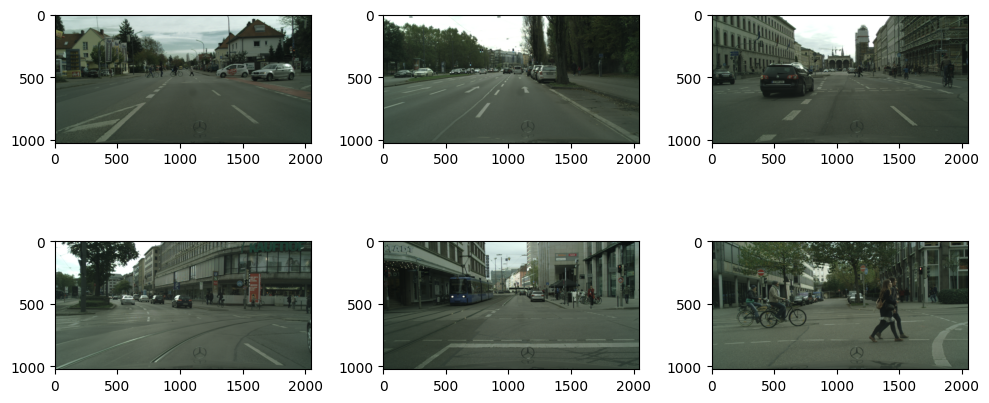

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, sample in zip(axes.flat, sample_paths_4):
    img = cv2.imread(str(sample))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)

plt.tight_layout()
plt.show()

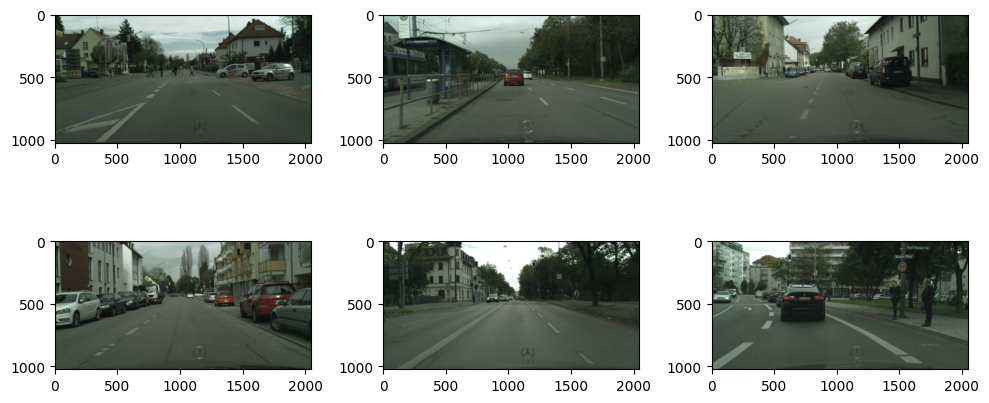

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, sample in zip(axes.flat, sample_paths_3):
    img = cv2.imread(str(sample))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)

plt.tight_layout()
plt.show()